# Семинар: RAG (Retrieval Augmented Generation)
RAG - это метод работы с большими языковыми моделями, когда к запросу пользователя добавляется дополнительная информация из каких‑то внешних источников и такой запрос подается на вход LLM.
Т.е. в контекст запроса к LLM добавляется дополнительная информация, на основе которой языковая модель может дать пользователю более полный и точный ответ.

Используется для создания вопросно-ответных систем.

## Основной алгоритм работы RAG следующий:

1.   Вся база знаний «нарезается» на небольшие куски текста - chunks (чанки). Размер чанков может варьироваться от нескольких строк, до нескольких абзацев, т.е. примерно 100 до 1000 слов.
2.   Чанки векторизуются и превращаются в эмбеддинги (вектора), которые описывают смысл чанка.
1.   Полученные вектора складываются в специальную базу данных (векторную).
2.   Когда пользователь отправляет свой вопрос в LLM, то текст его запроса кодируется в эмбеддинг и далее в базе данных производится поиск наиболее близких «по смыслу» эмбеддингов. Как правило, считается косинусная близость вектора запроса и вектора каждого чанка и далее выбираются топ N векторов наиболее близких к запросу.
1.   Далее текст чанков, соответствующий найденным векторам, вместе с запросом пользователя объединяется в единый контекст и подается на вход языковой модели. Т.е. модель «думает», что пользователь написал ей не только вопрос, но еще и предоставил данные на основе которых нужно ответить на поставленный вопрос.


    






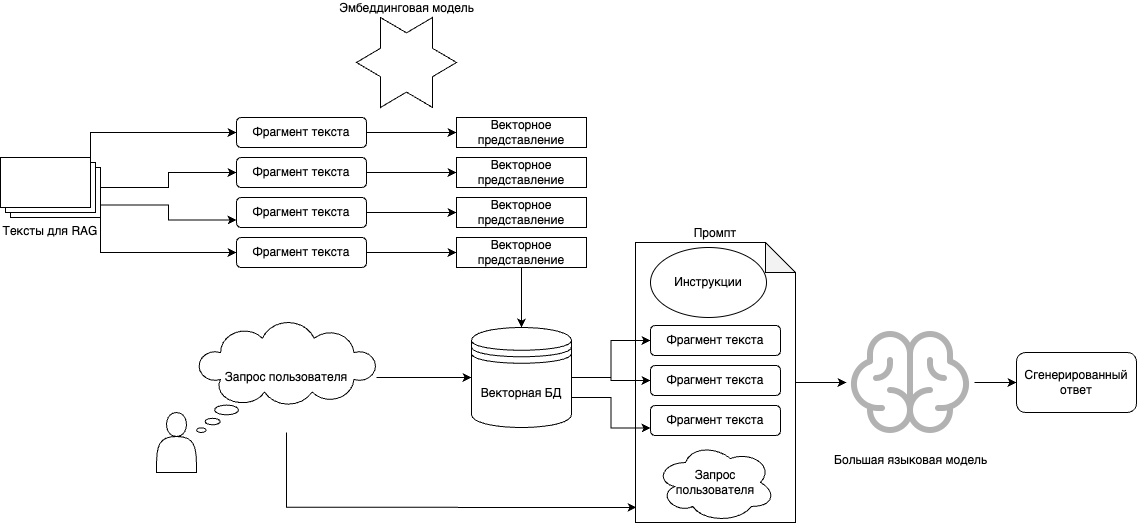

## Некоторые рекомендации.

**Размер чанков и их количество.** Рекомендуется начинать эксперименты с изменения размера чанков и их количества. Если на вход LLM подается слишком много ненужной информации или наоборот, слишком мало, то высока вероятность некачественного ответа модели:
*   Чем меньше чанк по размеру, тем точнее будет буквальный поиск, чем больше размер чанка тем больше поиск приближается к смысловому.
*   Разные запросы пользователя могут содержать разное количество чанков, которое необходимо добавлять в контекст. Необходимо опытным путем подобрать тот самый коэффициент, ниже которого чанк смысла не имеет и будет лишь замусоривать контекст.
*   Чанки должны перекрывать друг друга, чтобы был шанс подать на вход последовательность чанков, которые следуют друг за другом вместе, а не просто вырванные из контекста куски.
*    Начало и конец чанка должны быть осмысленными, в идеале должны совпадать с началом и концом предложения, а лучше абзаца, чтобы вся мысль была в чанке целиком.

**Добавление других методов поиска.** Очень часто поиск «по смыслу» через эмбеддинги не дает нужного результата. Особенно если речь идет о каких‑то специфических терминах или определениях. Как правило к поиску через эмбеддинги подключают также TF‑IDF поиск и объединяют результаты поиска в пропорции, подобранной экспериментальным путем. Также очень часто помогает ранжирование найденных результатов например алгоритмом BM25.

**Мультиплицирование запроса.** Как правило, запрос от пользователя имеет смысл несколько раз перефразировать (с помощью LLM) и осуществлять поиск чанков по всем вариантам запроса. На практике сделают от 3-х до 5-ти вариаций запросов и потом результаты поиска объединяют в один.

**Суммаризация чанков.** Если по запросу пользователя найдено очень много информации и вся эта информация не помещается в контекст, то ее можно «упростить» с помощью LLM и подать на вход в виде контекста (в добавление к вопросу пользователя) нечто вроде заархивированного знания, чтобы LLM могла использовать суть (выжимку из базы знаний) при формировании ответа.

**Системный промпт и дообучение модели на формат RAG.** Чтобы модель лучше понимала, что от нее требуется возможно также дообучить LLM на правильный формат взаимодействия с ней. В подходе RAG контекст, всегда состоит из двух частей: вопроса пользователя и найденного контекста. Соответственно модель через системный промпт можно дообучить понимать именно такой формат: тут вопрос, тут информация для ответа, выдай ответ, к вопросу.

## Векторизация (эмбединг) текста
Векторизация – это подход к преобразованию входных данных из их исходного формата (например, текста) в векторы действительных чисел, которые понятны моделям машинного обучения. Эмбеддинг - результат процесса преобразования языковой сущности – слова, предложения, параграфа или целого текста в набор чисел – числовой вектор.

Методы векторизации:
1. Мешок слов.
2. TF-IDF.
3. Алгоритм Word2Vec.
4. GloVe.
5. FastText.



## Ретриверы

Ретривер - осуществляет поиск наиболее близких «по смыслу» эмбеддингов.

Ретривер на основе эмбеддинговой модели сравнивает между собой эмбеддинги чанков в БД и пользовательские запросы пользователя по косинусному сходству или другой метрике близости. Качество сравнения/поиска определяется качеством эмбедингов, поскольку вектор представляет собой числовое представление семантического смысла.

Модель BM25 (Best Matching 25) основана на векторизации TF-IDF, т.е. модели BM25 векторизируют текст по словам. Поэтому поиск с помощью BM25 - это поиск по ключевым словам. Поскольку BM25 работает со словами, а не со смыслами, нужно как в классическом NLP выполнить предобработку текстов, чтобы уменьшить словарь.

Можно использовать гибрид, где некоторые фрагменты извлекаются по одной модели, а другие - по другой.

Рейтинг ретриверов для английского языка - https://huggingface.co/spaces/mteb/leaderboard

Рейтинг ретриверов для русского языка - https://github.com/avidale/encodechka#%D0%BB%D0%B8%D0%B4%D0%B5%D1%80%D0%B1%D0%BE%D1%80%D0%B4

Пример эмбеддинговой модели - https://huggingface.co/sentence-transformers/paraphrase-multilingual-mpnet-base-v2

## Вариант реализации

- `faiss-cpu` - используем векторное хранилище FAISS для размещения чанков (фрагментов текстов для контекста) и эмбеддингов (векторных представлений) этих чанков;
- `sentence-transformers` - библиотека для локального использования эмбеддинговых моделей с ресурса Hugging Face;
- `rank_bm25` - библиотека для работы с алгоритмами векторизации BM25 (вариации TF-IDF).

In [ ]:
!pip install langchain-gigachat langchain langchain_community langchain_huggingface faiss-cpu rank_bm25

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.1/45.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 548.1/548.1 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 3.1 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.3.1
    Uninstalling langchain-core-1.3.1:
      Successfully uninstalled langchain-core-1.3.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed

In [ ]:
from google.colab import userdata
auth = userdata.get('GigaChatKey')

In [ ]:
#from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_huggingface.embeddings import HuggingFaceEndpointEmbeddings
#from langchain_community.retrievers import BM25Retriever
from langchain.retrievers import BM25Retriever, EnsembleRetriever
from langchain_community.vectorstores.faiss import FAISS
from langchain_core.documents import Document

from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter #Разделение на основе токенов
from langchain_text_splitters import CharacterTextSplitter #Разделение на основе символов

from langchain_core.prompts import PromptTemplate
from langchain_gigachat.chat_models import GigaChat

ModuleNotFoundError: No module named 'langchain.retrievers'

In [ ]:
#Создание загрузчика документов
loader = WebBaseLoader(["https://habr.com/ru/articles/876844", "https://habr.com/ru/articles/979064/", "https://habr.com/ru/articles/918048/"])
docs = loader.load()

In [ ]:
#Создание разделителя документов для формирования чанков
text_splitter = CharacterTextSplitter(
    separator="\n\n",
    chunk_size=500,
    chunk_overlap=0,
    length_function=len,
    is_separator_regex=False
)
text_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)

split_docs = text_splitter.split_documents(docs)
len(split_docs), split_docs[0]

(209,
 Document(metadata={'source': 'https://habr.com/ru/articles/876844', 'title': 'Используем языковые модели в AI-агентах. Часть 2. Retrievers, TextSplitters / Хабр', 'description': 'Привет, Хабр! Это вторая часть серии статьей, посвященной использованию языковых моделей. В прошлой статье я рассмотрел основные элементы, с которыми приходится работать в библиотеке Langchain. Во...', 'language': 'ru'}, page_content='Используем языковые модели в AI-агентах. Часть 2. Retrievers, TextSplitters / Хабр'))

In [ ]:
#Использование эмбединговой модели. Формирование векторной БД
embeddings = HuggingFaceEndpointEmbeddings(model="mixedbread-ai/mxbai-embed-large-v1", task="feature-extraction")
vector_store = FAISS.from_documents(split_docs, embedding=embeddings)

In [ ]:
#Задание параметров извлечения. Например, возвращать 5 фрагментов, наиболее близких по смыслу.
embedding_retriever = vector_store.as_retriever(search_kwargs={"k": 5})

In [ ]:
prompt = "Принципы разделения на фрагменты"

In [ ]:
adddoc = embedding_retriever.invoke(prompt)
adddoc

[Document(id='a9884673-b2e1-497f-99be-7830e2ee5d24', metadata={'source': 'https://habr.com/ru/articles/876844', 'title': 'Используем языковые модели в AI-агентах. Часть 2. Retrievers, TextSplitters / Хабр', 'description': 'Привет, Хабр! Это вторая часть серии статьей, посвященной использованию языковых моделей. В прошлой статье я рассмотрел основные элементы, с которыми приходится работать в библиотеке Langchain. Во...', 'language': 'ru'}, page_content='также пытается сохранить целостность объектов, но она может быть нарушена, если будет неверно задан максимальный размер фрагмента.Пример данных: {'),
 Document(id='fcc23d25-edb3-4873-9719-210a3789ca7e', metadata={'source': 'https://habr.com/ru/articles/876844', 'title': 'Используем языковые модели в AI-агентах. Часть 2. Retrievers, TextSplitters / Хабр', 'description': 'Привет, Хабр! Это вторая часть серии статьей, посвященной использованию языковых моделей. В прошлой статье я рассмотрел основные элементы, с которыми приходится работать

In [ ]:
addinform = "\n\n".join(i.page_content for i in adddoc)
addinform

'также пытается сохранить целостность объектов, но она может быть нарушена, если будет неверно задан максимальный размер фрагмента.Пример данных: {\n\nкомпанийДокументыСоглашениеКонфиденциальностьУслугиКорпоративный блогМедийная рекламаНативные проектыОбразовательные программыСтартапамVKTelegramYoutubeЯндекс Дзен Настройка языкаТехническая поддержка© 2006–2026, Habr\n\nстатье я постарался разобрать разделение и хранение данных. Конечно, предварительная обработка на этом не заканчивается, так как в тексте могут встречаться специальные символы, например, смайлики, которые тоже нужно как то обработать.Важно помнить, что обработка текста  - один из главных этапов работы с языковыми моделями, так как от правильности и полноты  входных данных зависит дальнейшая работа языковой модели. В следующей части разберем создание собственных инструментов (Tools) и работу с\n\nпокажу её базовые реализации. Для примеров я буду использовать  фреймворк LangGraph\xa0— его основы я разбирал в\xa0предыдущей 

In [ ]:
llm = GigaChat(
    credentials=auth,
    scope="GIGACHAT_API_PERS",
    model="GigaChat-Pro",
    temperature=0.1,
    verify_ssl_certs=False
)

prompt_template = PromptTemplate.from_template('''Ответь на вопрос пользователя. \
Используй при этом только информацию из контекста. Если в контексте нет \
информации для ответа, сообщи об этом пользователю.
Контекст: {context}
Вопрос: {input}
Ответ:'''
)

chain = prompt_template | llm

In [ ]:
chain.invoke({"input": prompt, "context": addinform}).content

'В предоставленном контексте информация о конкретных принципах разделения на фрагменты отсутствует. Упоминается лишь общая проблема целостности объектов при неверно заданном максимальном размере фрагмента.'

In [ ]:
#Используем ретривер BM25
import string
def tokenize(s):
    return s.lower().translate(str.maketrans("", "", string.punctuation)).split(" ")

bm25_retriever = BM25Retriever.from_documents(
      documents=split_docs,
      preprocess_func=tokenize,
      k=5,
  )

adddoc = bm25_retriever.get_relevant_documents(prompt)
adddoc

[Document(metadata={'source': 'https://habr.com/ru/articles/876844', 'title': 'Используем языковые модели в AI-агентах. Часть 2. Retrievers, TextSplitters / Хабр', 'description': 'Привет, Хабр! Это вторая часть серии статьей, посвященной использованию языковых моделей. В прошлой статье я рассмотрел основные элементы, с которыми приходится работать в библиотеке Langchain. Во...', 'language': 'ru'}, page_content="Primary schools have from 50-200 pupils.Как видим, текст был разделен на фрагменты  примерно по 500 символов по строке 'are'. Помимо этого, благодаря chunk_overlap,  второй фрагмент начинается с предложения на котором закончился первый фрагмент. Наглядный пример разделения на фрагменты и перекрытия фрагментов:Демонстрация доступна по ссылке: https://chunkviz.up.railway.app/А также, если хотите больше узнать про разделение текста не только в"),
 Document(metadata={'source': 'https://habr.com/ru/articles/876844', 'title': 'Используем языковые модели в AI-агентах. Часть 2. Retrieve

In [ ]:
addinform = "\n\n".join(i.page_content for i in adddoc)
addinform

'Primary schools have from 50-200 pupils.Как видим, текст был разделен на фрагменты  примерно по 500 символов по строке \'are\'. Помимо этого, благодаря chunk_overlap,  второй фрагмент начинается с предложения на котором закончился первый фрагмент. Наглядный пример разделения на фрагменты и перекрытия фрагментов:Демонстрация доступна по ссылке: https://chunkviz.up.railway.app/А также, если хотите больше узнать про разделение текста не только в\n\ntext_union = f.read()Разделим документ на фрагменты с помощью split_text. Распечатаем фрагменты с указанием их длины:chunks = text_splitter.split_text(text_union)\n\nmodel_id = "microsoft/Phi-3-mini-4k-instruct"\ntokenizer = AutoTokenizer.from_pretrained(model_id)Воспользуемся метод from_huggingface_tokenizer, который предоставляет CharacterTextSplitter и установим небольшое значение chunk_size:text_splitter = CharacterTextSplitter.from_huggingface_tokenizer(\n    tokenizer, chunk_size=100, chunk_overlap=0\n)Разделим текст на фрагменты, посмот

In [ ]:
chain.invoke({"input": prompt, "context": addinform}).content

'Принципы разделения текста на фрагменты включают следующие аспекты:\n\n1. **Фиксированная длина фрагмента**: Текст делится на части заданной длины (например, около 500 символов).\n   \n2. **Перекрытие фрагментов (overlap)**: Второй фрагмент частично повторяет конец предыдущего, обеспечивая контекстуальную связность между частями.\n\n3. **Использование специальных методов**: Например, `split_text` и `create_documents`, которые позволяют гибко настраивать параметры деления текста.\n\n4. **Настройка размера фрагмента и перекрытия**: Параметры вроде `chunk_size` и `chunk_overlap` задают размер фрагментов и величину перекрытия соответственно.\n\nТаким образом, принципы заключаются в делении текста на управляемые части с учетом сохранения смысловых связей через перекрытие.'

In [ ]:
#Если используем ансамблевый ретривер
embedding_retriever = vector_store.as_retriever(search_kwargs={"k": 2})
bm25_retriever = BM25Retriever.from_documents(
    documents=split_docs,
    preprocess_func=tokenize,
    k=3,
)

ensemble_retriever = EnsembleRetriever(
    retrievers=[embedding_retriever, bm25_retriever],
    weights=[0.4, 0.6],
)

adddoc = ensemble_retriever.invoke(prompt)
adddoc

[Document(metadata={'source': 'https://habr.com/ru/articles/876844', 'title': 'Используем языковые модели в AI-агентах. Часть 2. Retrievers, TextSplitters / Хабр', 'description': 'Привет, Хабр! Это вторая часть серии статьей, посвященной использованию языковых моделей. В прошлой статье я рассмотрел основные элементы, с которыми приходится работать в библиотеке Langchain. Во...', 'language': 'ru'}, page_content="Primary schools have from 50-200 pupils.Как видим, текст был разделен на фрагменты  примерно по 500 символов по строке 'are'. Помимо этого, благодаря chunk_overlap,  второй фрагмент начинается с предложения на котором закончился первый фрагмент. Наглядный пример разделения на фрагменты и перекрытия фрагментов:Демонстрация доступна по ссылке: https://chunkviz.up.railway.app/А также, если хотите больше узнать про разделение текста не только в"),
 Document(metadata={'source': 'https://habr.com/ru/articles/876844', 'title': 'Используем языковые модели в AI-агентах. Часть 2. Retrieve

## Рекомендации по выбору весов

| Тип данных | Рекомендуемые веса [embedding, BM25] | Объяснение |
|------------|--------------------------------------|------------|
| **Техдокументация/код** | [0.2, 0.8] - [0.4, 0.6] | Точные совпадения критически важны |
| **Научные статьи** | [0.6, 0.4] | Нужно понимание концепций и контекста |
| **Новости/блоги** | [0.7, 0.3] - [0.8, 0.2] | Много синонимов, разговорный стиль |
| **Юридические документы** | [0.3, 0.7] - [0.5, 0.5] | Точность формулировок + понимание контекста |
| **Медицинские тексты** | [0.5, 0.5] - [0.6, 0.4] | Терминология + семантическое понимание |
| **Соцсети/чаты** | [0.8, 0.2] - [0.9, 0.1] | Много опечаток, сленга, неформального языка |

## RAG на основе файлов
Можно использовать, например, UnstructuredWordDocumentLoader и UnstructuredPDFLoader для DOCX и PDF, соответственно, и CSVLoader и UnstructuredExcelLoader для CSV и XLSX.

In [ ]:
from langchain_community.document_loaders import UnstructuredPDFLoader
from langchain_community.document_loaders import UnstructuredWordDocumentLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100)

loader1 = UnstructuredPDFLoader('Имя_файла.pdf')
splitted_data = loader1.load_and_split(text_splitter)

loader2 = UnstructuredWordDocumentLoader('Имя_файла.docx')
splitted_docx = loader2.load_and_split(text_splitter)

In [ ]:
from langchain_community.document_loaders.csv_loader import CSVLoader
from langchain_community.document_loaders import UnstructuredExcelLoader

from glob import glob
files = glob('*.csv')

splitted_csv = []
for f in files: #Если нужно загрузить несколько csv-файлов
  loader3 = CSVLoader(f)
  splitted_csv.extend(loader3.load())

loader4 = UnstructuredExcelLoader('din-zatrat-rs.xlsx')
splitted_xlsx = loader4.load_and_split(text_splitter)

vector_store_xlsx = FAISS.from_documents(splitted_xlsx, embedding=embeddings)

## RAG на основе видеороликов
Для реализации такой системы необходимо:  
*   извлечь аудио из видео;
*   распознать речь, выполнив Speech2Text преобразование;
*   сформировать фрагменты текстов, чтобы в метаданных содержалась ссылка на ролик и таймкод (если необходима возможность перехода к указанному месту);
*   создать векторную базу данных из фрагментов;
*   составить пайплайн и реализовать систему.


## Общение с базой данных на естественном языке с помощью большой языковой модели

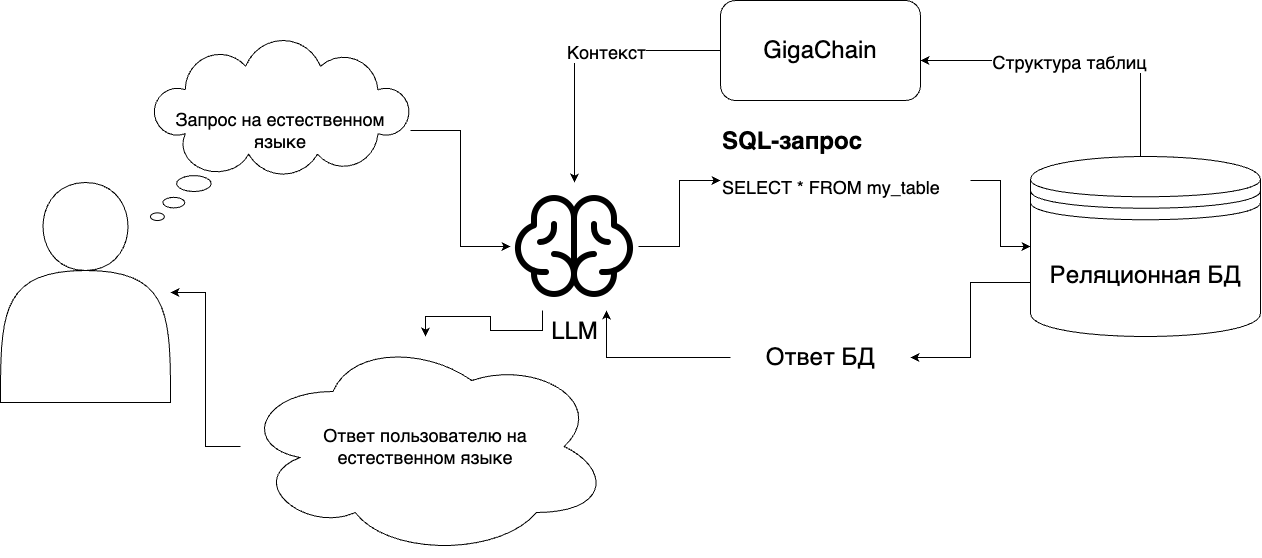

In [ ]:
from langchain_community.utilities import SQLDatabase
db = SQLDatabase.from_uri("sqlite:///" + db_path)
print(db.dialect)
print(db.get_usable_table_names())
db.run("SELECT * FROM users LIMIT 10;")

from langchain.chains import create_sql_query_chain
chain = create_sql_query_chain(llm, db)
response = chain.invoke({"question": "Какие ФИО пользователей есть в БД?"})

from langchain_community.tools.sql_database.tool import QuerySQLDataBaseTool
from langchain.globals import set_verbose, set_debug
set_verbose(True)
set_debug(False)
execute_query = QuerySQLDataBaseTool(db=db)
write_query = create_sql_query_chain(llm, db)
extract_sql_query = "Здесь можно написать функцию для извлечения SQL-запроса из ответа БЯМ"

chain = write_query | extract_sql_query | execute_query
chain.invoke({"question": "Кто наши пользователи?"})

##Задание на семинар
Известны следующие подходы, используемые в RAG-системах: мультиплицирование запроса и суммаризация чанков.

**Мультиплицирование запроса** - подход, при котором запрос от пользователя несколько раз перефразируется с помощью LLM и осуществляется поиск чанков по всем вариантам запроса. Результаты поиска объединяют в один.

**Суммаризация чанков**  - подход, при котором найденные чанки «упрощаются» с помощью LLM (например, создается выжимка), а затем подаются на вход в LLM (добавляются к запросу пользователя).

1. Реализуйте мультиплицирование запроса, когда запрос от пользователя перефразируется LLM 3-5 раз и для каждого варианта запроса осуществляется поиск чанков. Дубликаты чанков удаляются программным кодом. Найденные чанки подаются LLM (в цепочку). Перефразирование LLM реализуйте с помощью цепочки. Используйте ретривер BM25. Принцип деление на чанки - по абзацам.
1. Реализуйте суммаризацию чанков. Упрощение (выжимка) реализуйте с помощью цепочки.

In [ ]:
# Установка необходимых библиотек
!pip install langchain-gigachat langchain langchain_community langchain_huggingface faiss-cpu rank_bm25

from google.colab import userdata
auth = userdata.get('GigaChatKey')

from langchain_huggingface.embeddings import HuggingFaceEndpointEmbeddings
from langchain.retrievers import BM25Retriever
from langchain_community.vectorstores.faiss import FAISS
from langchain_core.documents import Document
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import CharacterTextSplitter
from langchain_core.prompts import PromptTemplate
from langchain_gigachat.chat_models import GigaChat

import string

ModuleNotFoundError: No module named 'langchain.retrievers'

In [ ]:
# Загрузка документов
loader = WebBaseLoader([
    "https://habr.com/ru/articles/876844",
    "https://habr.com/ru/articles/979064/",
    "https://habr.com/ru/articles/918048/"
])
docs = loader.load()

# Разделение на чанки по абзацам (принцип - по абзацам)
text_splitter = CharacterTextSplitter(
    separator="\n\n",  # Разделение по абзацам
    chunk_size=500,
    chunk_overlap=0,
    length_function=len,
    is_separator_regex=False
)

split_docs = text_splitter.split_documents(docs)
print(f"Количество чанков: {len(split_docs)}")

In [ ]:
# Функция токенизации для BM25
def tokenize(s):
    return s.lower().translate(str.maketrans("", "", string.punctuation)).split(" ")

# Создание BM25 ретривера
bm25_retriever = BM25Retriever.from_documents(
    documents=split_docs,
    preprocess_func=tokenize,
    k=5,  # Возвращаем 5 фрагментов для каждого запроса
)

# Инициализация LLM
llm = GigaChat(
    credentials=auth,
    scope="GIGACHAT_API_PERS",
    model="GigaChat-Pro",
    temperature=0.1,
    verify_ssl_certs=False
)

In [ ]:
# Цепочка для перефразирования запроса
multi_query_prompt = PromptTemplate.from_template('''Перефразируй следующий вопрос пользователя. \
Напиши только перефразированный вопрос, без лишних слов. \
Сохрани смысл исходного вопроса.

Исходный вопрос: {input}
Перефразированный вопрос:''')

multi_query_chain = multi_query_prompt | llm

def multiply_query(original_query, n_variants=4):
    """Генерирует n вариантов перефразирования запроса"""
    variants = [original_query]

    while len(variants) < n_variants:
        response = multi_query_chain.invoke({"input": original_query})
        variant = response.content.strip()
        if variant and variant not in variants:
            variants.append(variant)
    return variants

# Функция для мультиплицирования запроса и поиска чанков
def retrieve_with_multi_query(query, n_variants=4):
    """Поиск чанков с мультиплицированием запроса"""
    variants = multiply_query(query, n_variants)
    print(f"Сгенерированные варианты запроса:")
    for i, var in enumerate(variants):
        print(f"  {i+1}. {var}")

    # Поиск чанков для каждого варианта
    all_docs = []
    for variant in variants:
        docs = bm25_retriever.get_relevant_documents(variant)
        all_docs.extend(docs)

    # Удаление дубликатов (по содержимому)
    unique_docs = []
    seen_content = set()
    for doc in all_docs:
        if doc.page_content not in seen_content:
            seen_content.add(doc.page_content)
            unique_docs.append(doc)

    print(f"Найдено чанков до удаления дубликатов: {len(all_docs)}")
    print(f"После удаления дубликатов: {len(unique_docs)}")

    return unique_docs

# Тестирование мультиплицирования
prompt = "Принципы разделения на фрагменты"
print("\n=== МУЛЬТИПЛИЦИРОВАНИЕ ЗАПРОСА ===\n")
retrieved_docs = retrieve_with_multi_query(prompt, n_variants=4)

# Формирование контекста
context = "\n\n".join([doc.page_content for doc in retrieved_docs])

# Ответ LLM с найденными чанками
answer_prompt = PromptTemplate.from_template('''Ответь на вопрос пользователя. \
Используй при этом только информацию из контекста. Если в контексте нет \
информации для ответа, сообщи об этом пользователю.

Контекст: {context}
Вопрос: {input}
Ответ:''')

answer_chain = answer_prompt | llm
response = answer_chain.invoke({"input": prompt, "context": context})
print("\n=== ОТВЕТ LLM ===\n")
print(response.content)

In [ ]:
# Цепочка для суммаризации (создания выжимки) одного чанка
summarization_prompt = PromptTemplate.from_template('''Создай краткую выжимку (суммаризацию) следующего текста. \
Сохрани только самую важную информацию. Выжимка должна быть краткой и информативной.

Исходный текст: {chunk}
Краткая выжимка:''')

summarization_chain = summarization_prompt | llm

def summarize_chunk(chunk_text):
    """Суммаризация одного чанка"""
    response = summarization_chain.invoke({"chunk": chunk_text})
    return response.content.strip()

def retrieve_with_summarization(query, k=5):
    """Поиск чанков и их суммаризация"""
    # Поиск чанков через BM25
    docs = bm25_retriever.get_relevant_documents(query)

    print(f"Найдено {len(docs)} чанков. Выполняется суммаризация...")

    # Суммаризация каждого чанка
    summarized_docs = []
    for i, doc in enumerate(docs):
        print(f"  Суммаризация чанка {i+1}/{len(docs)}...")
        summary = summarize_chunk(doc.page_content)
        summarized_docs.append(summary)

    # Объединение выжимок
    summarized_context = "\n\n=== ВЫЖИМКА ИЗ ЧАНКА ===\n\n".join(summarized_docs)

    return summarized_context, docs

# Тестирование суммаризации
print("\n=== СУММАРИЗАЦИЯ ЧАНКОВ ===\n")
summarized_context, original_docs = retrieve_with_summarization(prompt, k=5)

print("\n=== ПРИМЕР ОРИГИНАЛЬНОГО ЧАНКА ===\n")
print(original_docs[0].page_content[:300] + "...")

print("\n=== ПРИМЕР ВЫЖИМКИ ЧАНКА ===\n")
print(summarized_context[:500] + "...")

# Ответ LLM с суммаризированными чанками
response_summarized = answer_chain.invoke({"input": prompt, "context": summarized_context})
print("\n=== ОТВЕТ LLM (НА ОСНОВЕ ВЫЖИМОК) ===\n")
print(response_summarized.content)

In [ ]:
# Демонстрация работы мультиплицирования запроса
def demonstrate_multi_query():
    print("=" * 60)
    print("ДЕМОНСТРАЦИЯ МУЛЬТИПЛИЦИРОВАНИЯ ЗАПРОСА")
    print("=" * 60)

    test_query = "Как правильно разделять текст на фрагменты?"

    # Получение чанков через мультиплицирование
    docs = retrieve_with_multi_query(test_query, n_variants=4)
    context = "\n\n".join([doc.page_content for doc in docs])

    # Получение ответа
    response = answer_chain.invoke({"input": test_query, "context": context})
    print(f"\nВопрос: {test_query}")
    print(f"\nОтвет: {response.content}")

# Демонстрация работы суммаризации
def demonstrate_summarization():
    print("\n" + "=" * 60)
    print("ДЕМОНСТРАЦИЯ СУММАРИЗАЦИИ ЧАНКОВ")
    print("=" * 60)

    test_query = "Какие принципы используются при разделении на фрагменты?"

    # Получение суммаризированных чанков
    summarized_context, _ = retrieve_with_summarization(test_query, k=3)

    # Получение ответа
    response = answer_chain.invoke({"input": test_query, "context": summarized_context})
    print(f"\nВопрос: {test_query}")
    print(f"\nОтвет: {response.content}")

# Запуск демонстрации
demonstrate_multi_query()
demonstrate_summarization()

In [ ]:
print("\n" + "=" * 60)
print("СРАВНИТЕЛЬНЫЙ АНАЛИЗ ПОДХОДОВ")
print("=" * 60)

comparison_query = "Что такое чанкинг в обработке текста?"

# Обычный поиск (без мультиплицирования)
regular_docs = bm25_retriever.get_relevant_documents(comparison_query)
regular_context = "\n\n".join([doc.page_content for doc in regular_docs])
regular_response = answer_chain.invoke({"input": comparison_query, "context": regular_context})

# Мультиплицирование
multi_docs = retrieve_with_multi_query(comparison_query, n_variants=4)
multi_context = "\n\n".join([doc.page_content for doc in multi_docs])
multi_response = answer_chain.invoke({"input": comparison_query, "context": multi_context})

# Суммаризация
summ_context, _ = retrieve_with_summarization(comparison_query, k=3)
summ_response = answer_chain.invoke({"input": comparison_query, "context": summ_context})

print("\n1. ОБЫЧНЫЙ ПОИСК (без обработки):")
print(f"   Найдено чанков: {len(regular_docs)}")
print(f"   Ответ: {regular_response.content[:200]}...")

print("\n2. МУЛЬТИПЛИЦИРОВАНИЕ ЗАПРОСА:")
print(f"   Найдено чанков (после удаления дубликатов): {len(multi_docs)}")
print(f"   Ответ: {multi_response.content[:200]}...")

print("\n3. СУММАРИЗАЦИЯ ЧАНКОВ:")
print(f"   Ответ: {summ_response.content[:200]}...")